**Stage 1 — Environment check**

In [19]:
import sys
import platform
print("Python version:", sys.version)
print("Python executable:", sys.executable)
print("Operating system:", platform.system())
print("OS version:", platform.version)


Python version: 3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]
Python executable: C:\Users\HomePC\AppData\Local\Programs\Python\Python314\python.exe
Operating system: Windows
OS version: <function version at 0x0000018C3A3E99B0>


**Stage 2 — Import required libraries**

In [20]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
    
)

print("TensorFlow version:", tf.__version__)
print("Numpy version:", tf.__version__)

TensorFlow version: 2.22.0-rc0
Numpy version: 2.22.0-rc0


**Stage 3 — Load Fashion MNIST**

In [21]:
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

print("Number of train images:", len(x_train))
print("Number  of test images:", len(x_test))
print("Number of train labels:", len(y_train))
print("Number of test labels:", len(y_test))

Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)
Number of train images: 60000
Number  of test images: 10000
Number of train labels: 60000
Number of test labels: 10000


**Stage 4 — Identify the classes**

In [22]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]
for labels, name in enumerate(class_names):
    print(f"{labels}: {name}")

0: T-shirt/top
1: Trouser
2: Pullover
3: Dress
4: Coat
5: Sandal
6: Shirt
7: Sneaker
8: Bag
9: Ankle boot


**Stage 5 — Explore the raw data**

In [23]:
print("Image shape:", x_train[0].shape)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())
print("First training label:", y_train[0])
print("First image class:", class_names[y_train[0]])


Image shape: (28, 28)
Minimum pixel value: 0
Maximum pixel value: 255
First training label: 5
First image class: Sandal


**Stage 6 — Visualize the first 12 images**

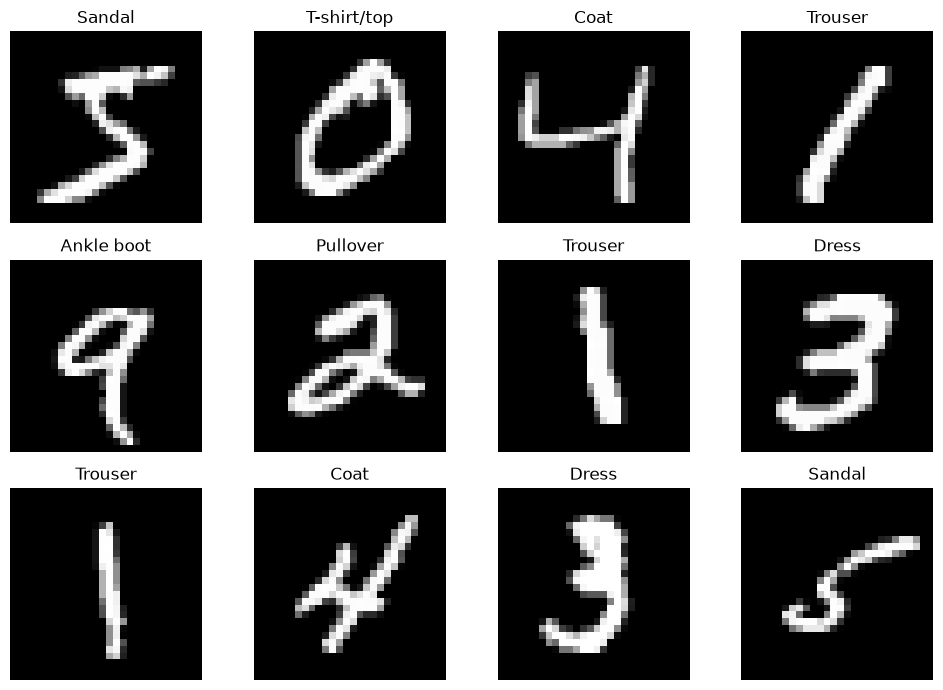

In [25]:
plt.figure(figsize=(10, 7))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

**Stage 7 — Normalize the images**

In [27]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Training pixel range:", x_train.min(), "to", x_train.max())
print("Test pixel range:", x_test.min(), "to", x_test.max())
print("Training data type:", x_train.dtype)
print("Test data type:", x_test.dtype)

Training pixel range: 0.0 to 0.003921569
Test pixel range: 0.0 to 0.003921569
Training data type: float32
Test data type: float32


**Stage 8 — Build the Sequential neural network**

In [31]:
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

print("Model ceated successfully.")

Model ceated successfully.


**Stage 9 — Inspect the model**

In [32]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

**Stage 10 — Compile the model**

In [39]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
print("Model compiled successfully.")

Model compiled successfully.


**Stage 11 — Train the model**

In [40]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.6913 - loss: 0.9690 - val_accuracy: 0.8503 - val_loss: 0.5228
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.8667 - loss: 0.4511 - val_accuracy: 0.8934 - val_loss: 0.3705
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8939 - loss: 0.3627 - val_accuracy: 0.9076 - val_loss: 0.3223
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9050 - loss: 0.3247 - val_accuracy: 0.9164 - val_loss: 0.2916
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9135 - loss: 0.2970 - val_accuracy: 0.9210 - val_loss: 0.2682
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9200 - loss: 0.2731 - val_accuracy: 0.9264 - val_loss: 0.2483
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9264 - loss: 0.2511 - val_accuracy: 0.9324 - val_loss: 0.2299
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9329 - loss: 0.23

**Stage 12 — Evaluate on unseen test data**

In [48]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=0
)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test accuracy percentage: {test_accuracy * 100:.2f}%")

Test loss: 0.1887
Test accuracy: 0.9431
Test accuracy percentage: 94.31%


**Stage 13 — Plot training and validation accuracy**

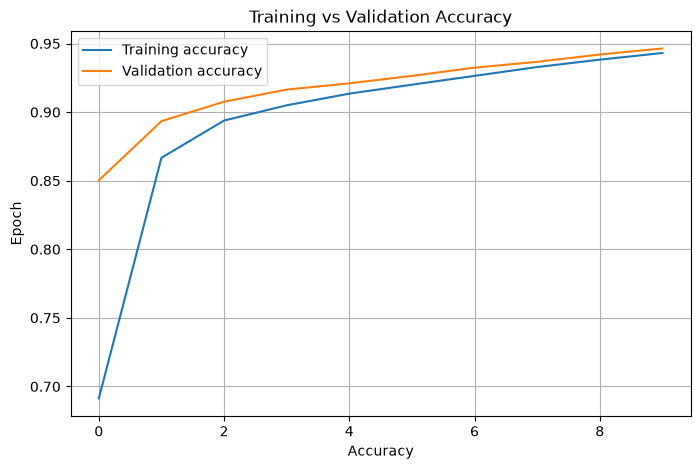

In [54]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")

plt.title("Training vs Validation Accuracy")
plt.xlabel("Accuracy")
plt.ylabel("Epoch")
plt.legend()
plt.grid(True)
plt.show()

**Stage 14 — Plot training and validation loss**

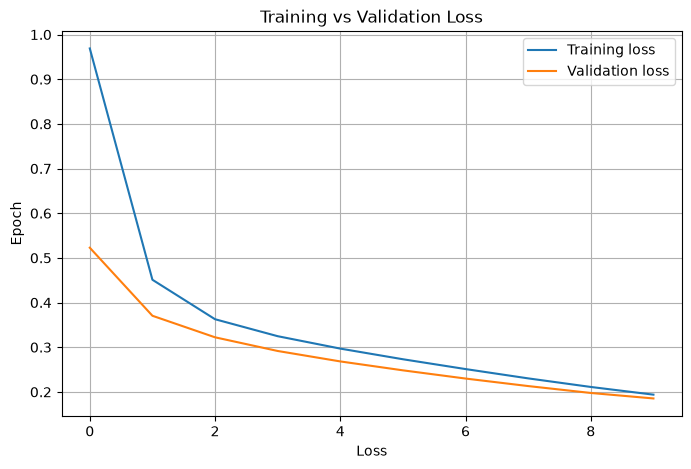

In [53]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Loss")
plt.ylabel("Epoch")
plt.legend()
plt.grid(True)
plt.show()

**Stage 15 — Generate predictions**

In [55]:
predictions = model.predict(x_test, verbose=1)
predicted_labels = np.argmax(predictions, axis=1)

print("Probability array shape:", predictions.shape)
print("Predicted labels shape:", predicted_labels.shape)
print("First 10 predictions:", predicted_labels[:10])
print("First 10 actual labels:", y_test[:10])


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Probability array shape: (10000, 10)
Predicted labels shape: (10000,)
First 10 predictions: [7 2 1 0 4 1 4 9 6 9]
First 10 actual labels: [7 2 1 0 4 1 4 9 5 9]


**Stage 16 — Visualize predictions**

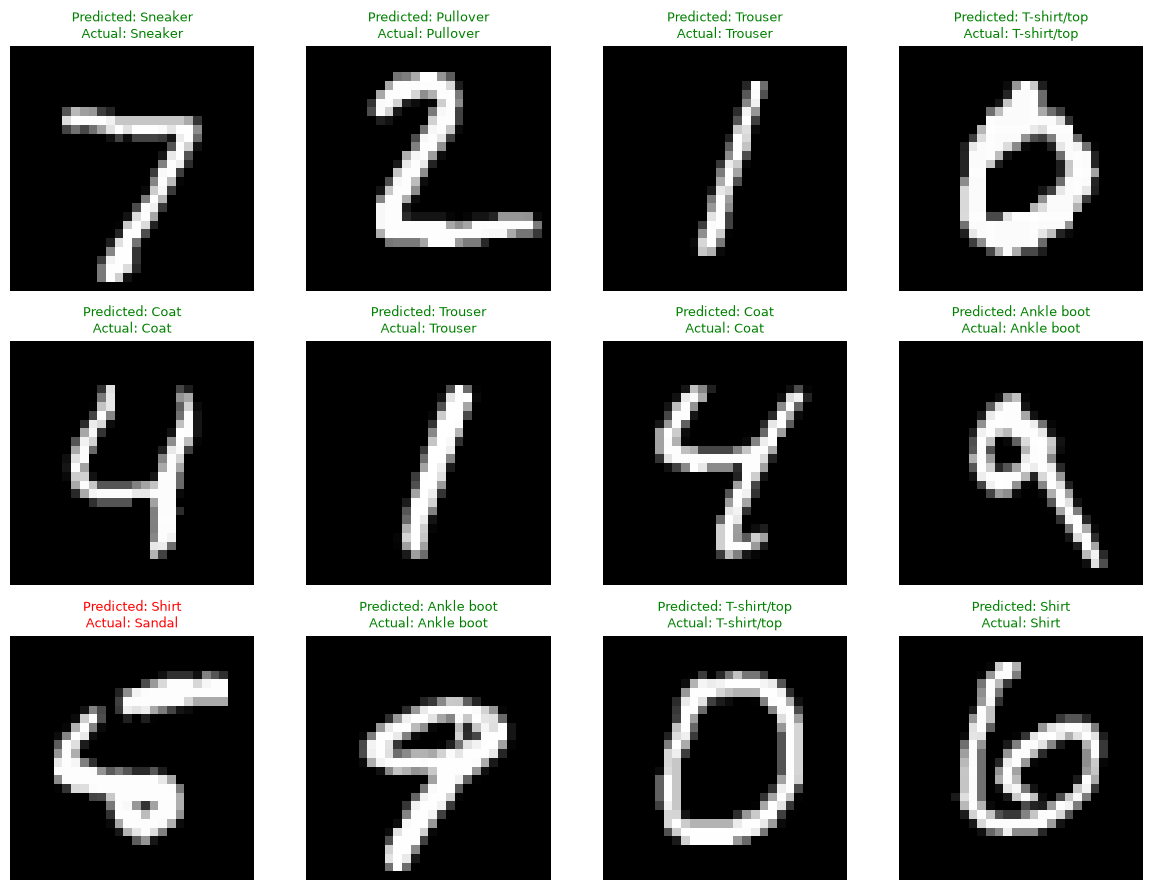

In [56]:
plt.figure(figsize=(12, 9))

for i in range(12):
    predicted = predicted_labels[i]
    actual = y_test[i]
    correct = predicted == actual

    plt.subplot(3, 4, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title(
        f"Predicted: {class_names[predicted]}\n"
        f"Actual: {class_names[actual]}",
        color="green" if correct else "red",
        fontsize=9
    )
    plt.axis("off")

plt.tight_layout()
plt.show()


**Stage 17 — Analyze incorrect predictions**

Correct predictions: 9431
Incorrect predictions: 569
Prediction accuracy: 0.9431
Prediction accuracy percentage: 94.31%


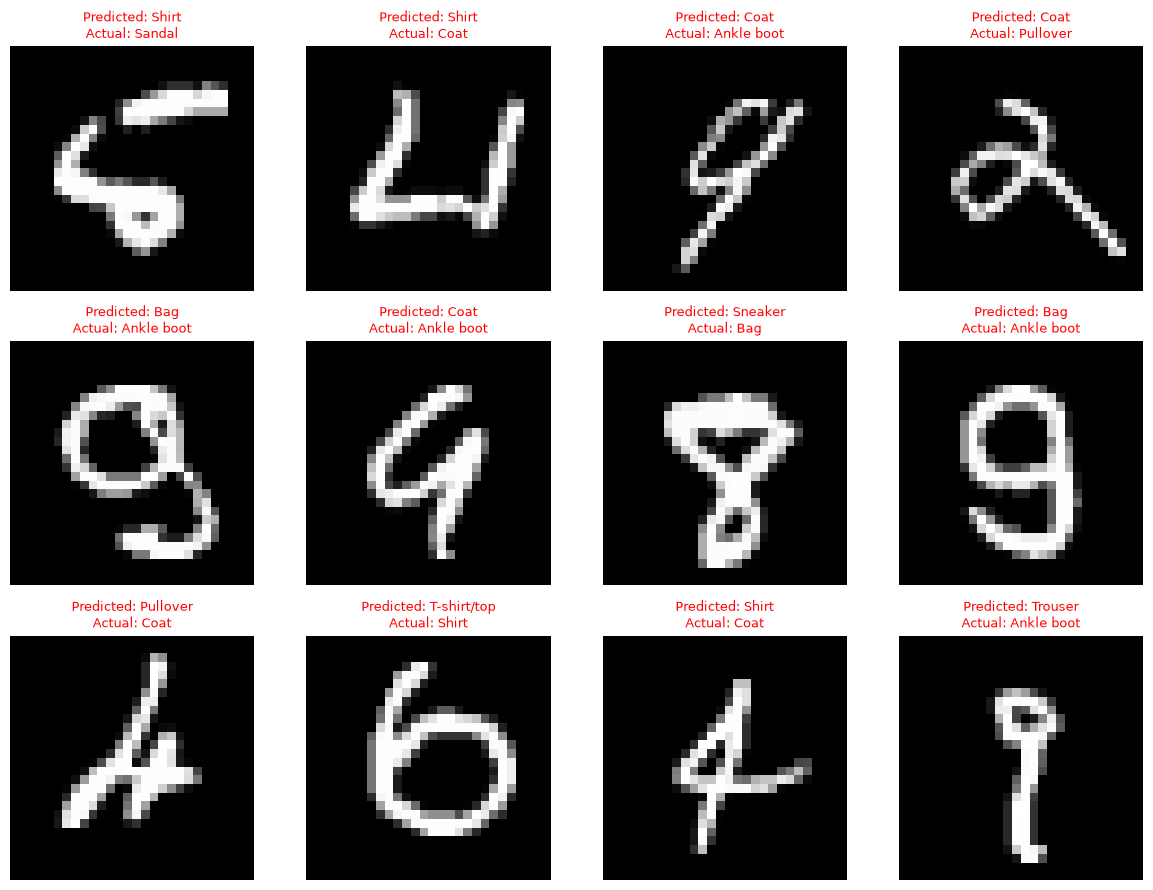

In [57]:
incorrect_indices = np.where(predicted_labels != y_test)[0]

correct_count = int(np.sum(predicted_labels == y_test))
incorrect_count = len(incorrect_indices)
prediction_accuracy = correct_count / len(y_test)

print("Correct predictions:", correct_count)
print("Incorrect predictions:", incorrect_count)
print(f"Prediction accuracy: {prediction_accuracy:.4f}")
print(f"Prediction accuracy percentage: {prediction_accuracy * 100:.2f}%")

num_to_show = min(12, incorrect_count)

if num_to_show > 0:
    plt.figure(figsize=(12, 9))

    for i in range(num_to_show):
        idx = incorrect_indices[i]

        plt.subplot(3, 4, i + 1)
        plt.imshow(x_test[idx], cmap="gray")
        plt.title(
            f"Predicted: {class_names[predicted_labels[idx]]}\n"
            f"Actual: {class_names[y_test[idx]]}",
            color="red",
            fontsize=9
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No incorrect predictions found.")

**Stage 18 — Create a confusion matrix**

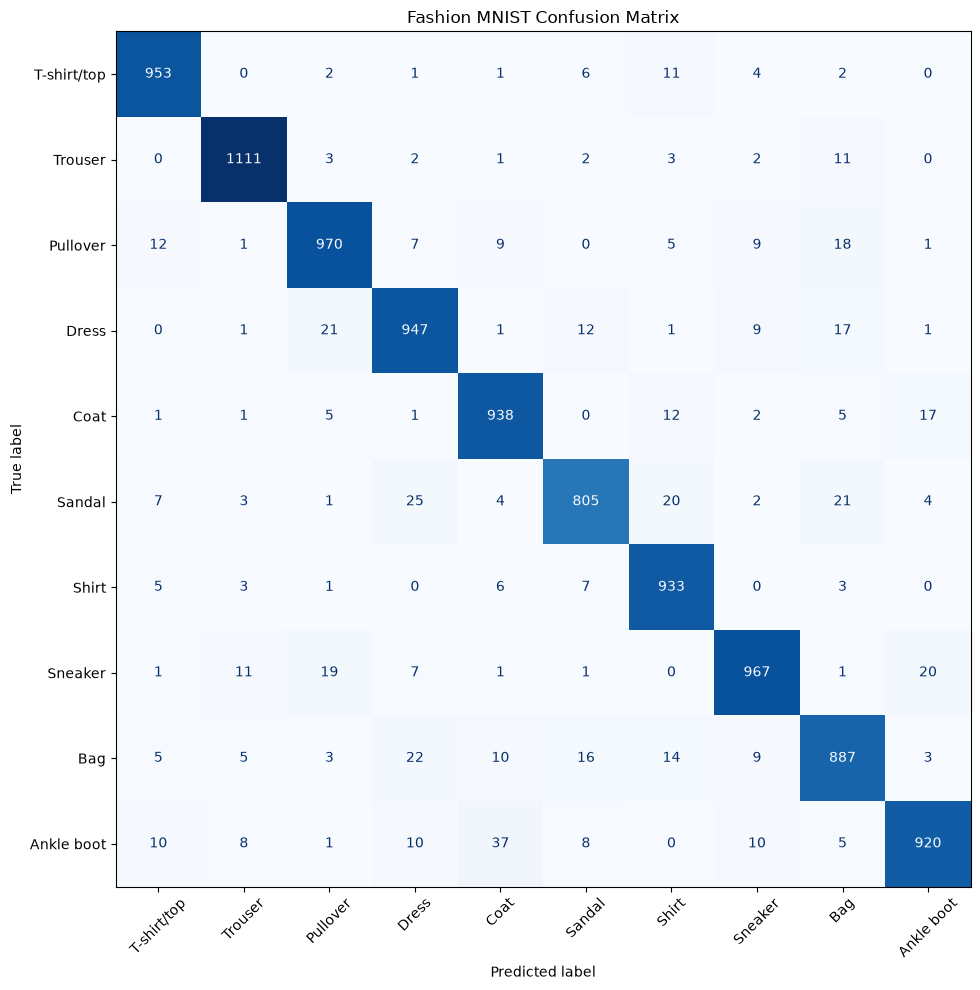

In [58]:
cm = confusion_matrix(
    y_test,
    predicted_labels,
    labels=np.arange(len(class_names))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(12, 10))
display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

plt.title("Fashion MNIST Confusion Matrix")
plt.tight_layout()
plt.show()

**To identify the most frequently confused pair of different classes, run this additional cell:**

In [59]:
cm_off_diagonal = cm.copy()
np.fill_diagonal(cm_off_diagonal, 0)

row, col = np.unravel_index(
    np.argmax(cm_off_diagonal),
    cm_off_diagonal.shape
)

print("Most frequent confusion:")
print("Actual class:", class_names[row])
print("Predicted class:", class_names[col])
print("Number of errors:", cm[row, col])


Most frequent confusion:
Actual class: Ankle boot
Predicted class: Coat
Number of errors: 37


**Stage 19 — Classification report**

In [60]:
report = classification_report(
    y_test,
    predicted_labels,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(report)

report_dict = classification_report(
    y_test,
    predicted_labels,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

f1_scores = {
    name: report_dict[name]["f1-score"]
    for name in class_names
}

weakest_class = min(f1_scores, key=f1_scores.get)

print("Class with weakest F1-score:", weakest_class)
print("F1-score:", round(f1_scores[weakest_class], 4))

              precision    recall  f1-score   support

 T-shirt/top     0.9588    0.9724    0.9656       980
     Trouser     0.9712    0.9789    0.9750      1135
    Pullover     0.9454    0.9399    0.9427      1032
       Dress     0.9266    0.9376    0.9321      1010
        Coat     0.9306    0.9552    0.9427       982
      Sandal     0.9393    0.9025    0.9205       892
       Shirt     0.9339    0.9739    0.9535       958
     Sneaker     0.9536    0.9407    0.9471      1028
         Bag     0.9144    0.9107    0.9126       974
  Ankle boot     0.9524    0.9118    0.9316      1009

    accuracy                         0.9431     10000
   macro avg     0.9426    0.9424    0.9423     10000
weighted avg     0.9432    0.9431    0.9430     10000

Class with weakest F1-score: Bag
F1-score: 0.9126


**Stage 20 — Predict one individual image**

Image index: 100
Predicted class: Shirt
Actual class: Shirt
Correct prediction: True


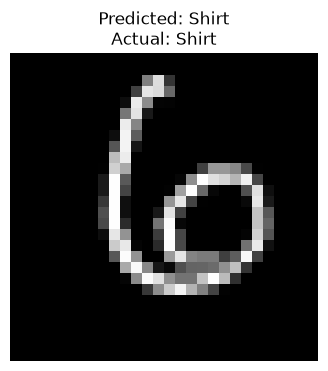

In [61]:
image_index = 100

single_image = x_test[image_index]
single_image_batch = np.expand_dims(single_image, axis=0)

single_prediction = model.predict(single_image_batch, verbose=0)
predicted_class = int(np.argmax(single_prediction[0]))
actual_class = int(y_test[image_index])

print("Image index:", image_index)
print("Predicted class:", class_names[predicted_class])
print("Actual class:", class_names[actual_class])
print("Correct prediction:", predicted_class == actual_class)

plt.figure(figsize=(4, 4))
plt.imshow(single_image, cmap="gray")
plt.title(
    f"Predicted: {class_names[predicted_class]}\n"
    f"Actual: {class_names[actual_class]}"
)
plt.axis("off")
plt.show()


**Stage 21 — Inspect all class probabilities**

In [62]:
for name, probability in zip(class_names, single_prediction[0]):
    print(f"{name:15s}: {probability:.4f} ({probability * 100:.2f}%)")

print(
    "\nHighest predicted probability:",
    f"{np.max(single_prediction[0]) * 100:.2f}%"
)


T-shirt/top    : 0.0001 (0.01%)
Trouser        : 0.0000 (0.00%)
Pullover       : 0.0091 (0.91%)
Dress          : 0.0000 (0.00%)
Coat           : 0.0002 (0.02%)
Sandal         : 0.0001 (0.01%)
Shirt          : 0.9904 (99.04%)
Sneaker        : 0.0000 (0.00%)
Bag            : 0.0001 (0.01%)
Ankle boot     : 0.0000 (0.00%)

Highest predicted probability: 99.04%


**Stage 22 — Save the trained model**

In [63]:
model.save("fashion_mnist_sequential_classifier.keras")

print("Model saved successfully.")


Model saved successfully.


**Stage 23 — Reload and verify the model**

In [64]:
loaded_model = load_model(
    "fashion_mnist_sequential_classifier.keras"
)

loaded_test_loss, loaded_test_accuracy = loaded_model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print(f"Original test accuracy: {test_accuracy:.6f}")
print(f"Reloaded test accuracy: {loaded_test_accuracy:.6f}")

print(
    "Accuracy difference:",
    f"{abs(test_accuracy - loaded_test_accuracy):.8f}"
)

print(
    "Results match:",
    np.isclose(test_accuracy, loaded_test_accuracy, atol=1e-5)
)

Original test accuracy: 0.943100
Reloaded test accuracy: 0.943100
Accuracy difference: 0.00000000
Results match: True


**Challenge A — Model interpretation**

In [65]:
# 1. Why do we normalize pixel values?

# We normalize pixel values from 0–255 to 0–1 by dividing them by 255. This gives the neural network smaller, consistent input values and can help training become more stable.

# 2. Why is `Flatten()` needed?

# Flatten converts each 28 × 28 image into a one-dimensional vector of 784 values so it can be passed into the Dense layers.

# 3. Why does the output layer contain 10 neurons?

# Fashion MNIST has 10 classes. Each output neuron represents one class.

# 4. Why is ReLU used in the hidden layers?

# ReLU introduces nonlinearity, allowing the network to learn complex patterns in clothing images.

# 5. Why is softmax used in the output layer?

# Softmax converts the output scores into probabilities across the 10 classes. The predicted class is the one with the highest probability.

# 6. Why should the test set remain separate from training?

# Keeping the test set separate provides a more independent estimate of how well the trained model performs on unseen data.

**Challenge B — Error analysis**

In [66]:
# The confusion matrix shows that the model sometimes misclassifies visually similar clothing categories. One frequently confused pair is [insert the actual class pair from the confusion matrix]

# A possible reason is that these categories have similar shapes, textures, or outlines in low-resolution 28 × 28 grayscale images. One way to improve the model would be to use a Convolutional Neural Network (CNN), which can learn spatial features such as edges, shapes, and patterns.

**Challenge C — Train a second model**

In [67]:

model_2 = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.3),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

model_2.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_2 = model_2.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

model_2_loss, model_2_accuracy = model_2.evaluate(
    x_test,
    y_test,
    verbose=0
)

print(f"Model 1 test accuracy: {test_accuracy * 100:.2f}%")
print(f"Model 2 test accuracy: {model_2_accuracy * 100:.2f}%")


Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.6611 - loss: 1.0635 - val_accuracy: 0.8443 - val_loss: 0.5539
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8387 - loss: 0.5307 - val_accuracy: 0.8990 - val_loss: 0.3603
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.8793 - loss: 0.4061 - val_accuracy: 0.9153 - val_loss: 0.2955
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8957 - loss: 0.3507 - val_accuracy: 0.9258 - val_loss: 0.2574
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9070 - loss: 0.3135 - val_accuracy: 0.9324 - val_loss: 0.2341
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9149 - loss: 0.2881 - val_accuracy: 0.9377 - val_loss: 0.2116
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9218 - loss: 0.2642 - val_accuracy: 0.9445 - val_loss: 0.1953
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9272 - loss: 0.2

**Challenge D — Final recommendation**

In [ ]:
# I would consider this model a useful baseline for a clothing-recognition application, but I would not deploy it in a real-world application without further testing. I would evaluate its test accuracy, per-class F1-scores, confusion matrix, and misclassified images to identify weaknesses. I would also compare it with a CNN and test it on images from real-world environments before deployment. This would help determine whether the model is sufficiently accurate and reliable for its intended use.